In [1]:
import pandas as pd
import numpy as npi
import matplotlib.pyplot as plt 
import seaborn as sns 

## COMPARE LLAMA VS QWEN SCORES

In [2]:
%cd ..

c:\Users\Merio\Desktop\PYTHON PROJECTS\SYNTHETIC SOCIAL MEDIA\Analysis


In [8]:
llama = pd.read_csv('Data/spinos_llama_scores.csv').reset_index().rename(columns= {'Index': 'ID'})
qwen= pd.read_csv('Data/spinos_qwen_scores.csv').reset_index().rename(columns= {'Index': 'ID'})

textdata = llama['content']
textdata.to_csv('textdata.csv')


In [ ]:
llama.head(5)

,index,content,topic,annotation,score
0,0,"Yes, they’re fully aware of what they’re doing...",nuclear-energy,favor,0.452609
1,1,The issue was with cost. And time from planni...,nuclear-energy,favor,0.533268
2,2,There's more renewables being built every year...,nuclear-energy,favor,0.443132
3,3,Author seems to not recognize the subs purpose...,nuclear-energy,s_against,0.426520
4,4,I know that’s funny. And that’s what has alway...,nuclear-energy,favor,0.432585
...,...,...,...,...,...
96,96,"&gt; shortened the lives of around 4,000 peopl...",nuclear-energy,favor,0.442338
97,97,I just read your link and he doesn't say solar...,nuclear-energy,undecided,0.456074
98,98,I find the accidents such an unfortunate set o...,nuclear-energy,s_favor,0.534681
99,99,There is a list of nuclear topics which the an...,nuclear-energy,favor,0.520507


In [52]:
qwen.head(5)

,content,topic,annotation,score
0,"Yes, they’re fully aware of what they’re doing...",nuclear-energy,favor,0.354734
1,The issue was with cost. And time from planni...,nuclear-energy,favor,0.427166
2,There's more renewables being built every year...,nuclear-energy,favor,0.287601
3,Author seems to not recognize the subs purpose...,nuclear-energy,s_against,0.322988
4,I know that’s funny. And that’s what has alway...,nuclear-energy,favor,0.344481


In [53]:
order = ['s_against', 'against', 'undecided', 'favor', 's_favor']

Text(0.5, 1.0, 'Llama scores')

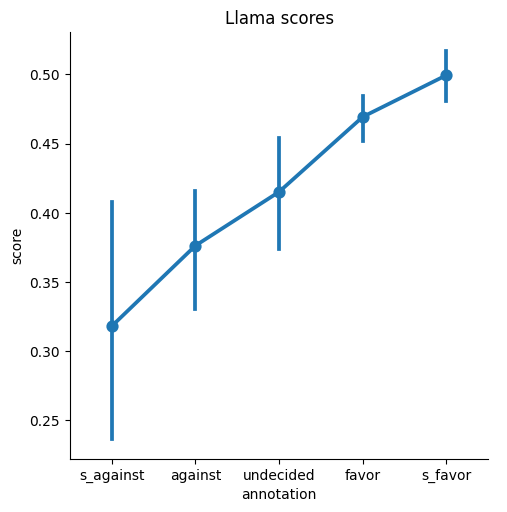

In [ ]:
sns.catplot(data = llama, x = 'annotation', y = 'score', order = order, kind = 'point')
plt.title('Llama scores')

Text(0.5, 1.0, 'qwen scores')

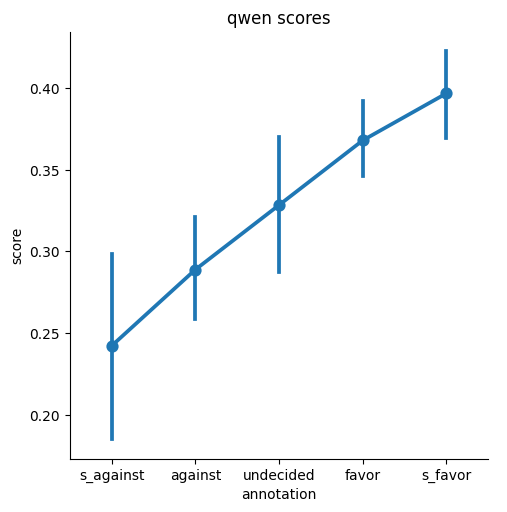

In [57]:
sns.catplot(data = qwen, x = 'annotation', y = 'score', order = order, kind = 'point')
plt.title('qwen scores')

In [82]:
full = pd.merge(llama, qwen[['index', 'score']], how = 'inner', on ='index')
full.rename(columns={'score_x': 'llama', 'score_y': 'qwen'}, inplace=True)

In [88]:
f2 = pd.melt(full, id_vars=['index', 'annotation'], value_vars=['llama', 'qwen'])
f2

,index,annotation,variable,value
0,0,favor,llama,0.452609
1,1,favor,llama,0.533268
2,2,favor,llama,0.443132
3,3,s_against,llama,0.426520
4,4,favor,llama,0.432585
...,...,...,...,...
197,96,favor,qwen,0.312958
198,97,undecided,qwen,0.388239
199,98,s_favor,qwen,0.447033
200,99,favor,qwen,0.387923


<Axes: xlabel='annotation', ylabel='value'>

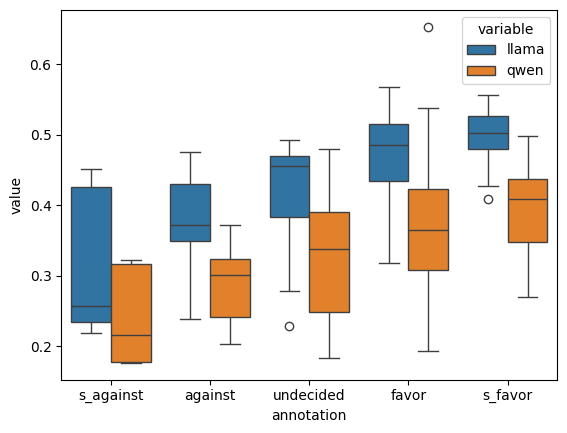

In [90]:
sns.boxplot(data =f2, x = 'annotation', y='value', hue='variable', order = order)

<Axes: xlabel='score', ylabel='annotation'>

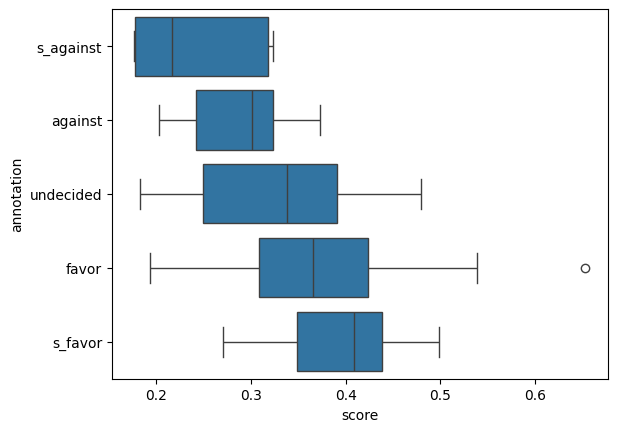

In [48]:
sns.boxplot(data = llama, x = 'score', y ='annotation', order = order)